In [1]:
import numpy as np
import os
import tensorflow as tf

SEED = 31415

def set_seed(seed=SEED):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'

set_seed()

2025-02-04 11:19:44.656060: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1738667984.697588   67918 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1738667984.708637   67918 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-04 11:19:44.774080: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import matplotlib.pyplot as plt
import warnings
from matplotlib import gridspec

plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)
plt.rc('image', cmap='magma')

warnings.filterwarnings("ignore") # to clean up output cells

In [3]:
from tensorflow.keras.preprocessing import image_dataset_from_directory

BATCH_SIZE=64
IMAGE_SIZE=[128, 128]

# Load training and validation sets
ds_train_ = image_dataset_from_directory(
    '../datasets/car-or-truck/train',
    labels='inferred',
    label_mode='binary',
    image_size=IMAGE_SIZE,
    interpolation='nearest',
    batch_size=BATCH_SIZE,
    shuffle=True,
)

ds_valid_ = image_dataset_from_directory(
    '../datasets/car-or-truck/valid',
    labels='inferred',
    label_mode='binary',
    image_size=IMAGE_SIZE,
    interpolation='nearest',
    batch_size=BATCH_SIZE,
    shuffle=False,
)

def convert_to_float(image, label):
    image = tf.image.convert_image_dtype(image, dtype=tf.float32)
    return image, label

AUTOTUNE = tf.data.experimental.AUTOTUNE
ds_train = (
    ds_train_
    .map(convert_to_float)
    .cache()
    .prefetch(buffer_size=AUTOTUNE)
)

ds_valid = (
    ds_valid_
    .map(convert_to_float)
    .cache()
    .prefetch(buffer_size=AUTOTUNE)
)

Found 5117 files belonging to 2 classes.


2025-02-04 11:19:50.847558: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 5051 files belonging to 2 classes.


In [4]:
from tensorflow import keras
from tensorflow.keras import layers

FILTERS = 32
PADDING = 'same'
ReLU, SIGMOID = 'relu', 'sigmoid'


model = keras.Sequential([
    layers.Input(shape=[*IMAGE_SIZE, 3]),
    
    # Block One
    layers.Conv2D(filters=FILTERS, kernel_size=3, activation=ReLU, padding=PADDING),
    layers.MaxPool2D(),

    # Block Two
    layers.Conv2D(filters=2*FILTERS, kernel_size=3, activation=ReLU, padding=PADDING),
    layers.MaxPool2D(),

    # Block Three
    layers.Conv2D(filters=4*FILTERS, kernel_size=3, activation=ReLU, padding=PADDING),
    layers.Conv2D(filters=4*FILTERS, kernel_size=3, activation=ReLU, padding=PADDING),
    layers.MaxPool2D(),

    # Head
    layers.Flatten(),
    layers.Dense(6, activation=ReLU),
    layers.Dropout(0.2),
    layers.Dense(1, activation=SIGMOID),
])

In [5]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(epsilon=0.01),
    # Add loss and metric
    loss='binary_crossentropy',
    metrics=['binary_accuracy']
)

In [6]:
EPOCHS = 50

history = model.fit(
    ds_train,
    validation_data=ds_valid,
    epochs=EPOCHS,
)

Epoch 1/50


2025-02-04 11:19:58.036932: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 134217728 exceeds 10% of free system memory.
2025-02-04 11:19:59.790044: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 134217728 exceeds 10% of free system memory.


 1/80 ━━━━━━━━━━━━━━━━━━━━ 9:04 7s/step - binary_accuracy: 0.5156 - loss: 0.6922

2025-02-04 11:20:00.631229: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 134217728 exceeds 10% of free system memory.
2025-02-04 11:20:02.117369: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 134217728 exceeds 10% of free system memory.


 2/80 ━━━━━━━━━━━━━━━━━━━━ 2:22 2s/step - binary_accuracy: 0.4961 - loss: 0.6947

2025-02-04 11:20:02.451222: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 134217728 exceeds 10% of free system memory.


80/80 ━━━━━━━━━━━━━━━━━━━━ 160s 2s/step - binary_accuracy: 0.5311 - loss: 0.6913 - val_binary_accuracy: 0.5785 - val_loss: 0.6797
Epoch 2/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 155s 2s/step - binary_accuracy: 0.5741 - loss: 0.6770 - val_binary_accuracy: 0.5787 - val_loss: 0.6637
Epoch 3/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - binary_accuracy: 0.5939 - loss: 0.6648 - val_binary_accuracy: 0.5785 - val_loss: 0.6585
Epoch 4/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - binary_accuracy: 0.5741 - loss: 0.6579 - val_binary_accuracy: 0.5785 - val_loss: 0.6523
Epoch 5/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - binary_accuracy: 0.5741 - loss: 0.6580 - val_binary_accuracy: 0.5787 - val_loss: 0.6498
Epoch 6/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - binary_accuracy: 0.5741 - loss: 0.6528 - val_binary_accuracy: 0.5787 - val_loss: 0.6423
Epoch 7/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - binary_accuracy: 0.6070 - loss: 0.6484 - val_binary_accuracy: 0.6221 - val_loss: 0.6354
Epoch 8/50
80/80 ━━━━━━━

<Axes: >

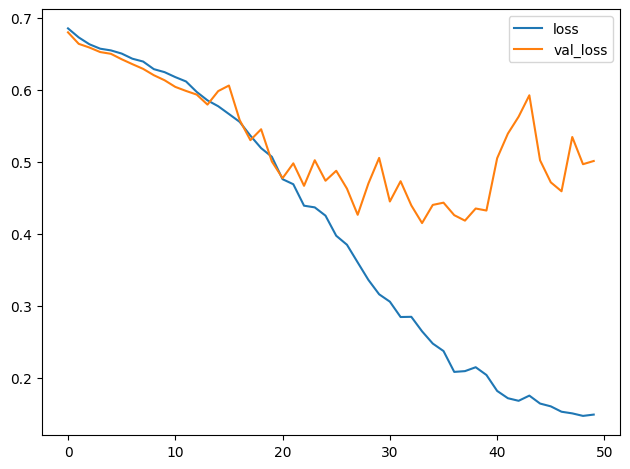

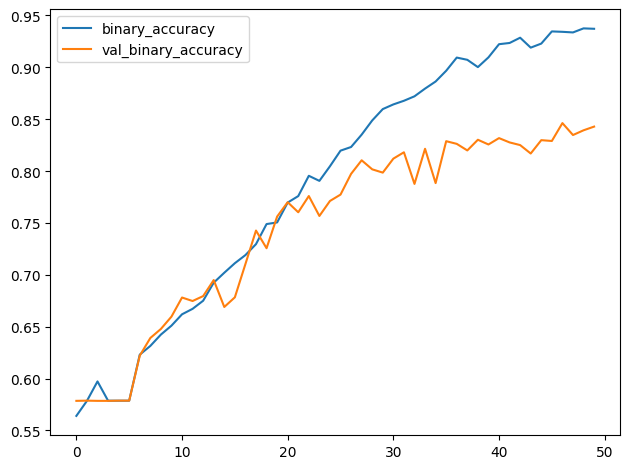

In [7]:
import pandas as pd

history_frame = pd.DataFrame(history.history)
history_frame.loc[:, ['loss', 'val_loss']].plot()
history_frame.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot()

In [8]:
from IPython.display import display, Markdown

content = f"""
**Q**: **How would you interpret these training curves? Did this model improve upon the model from the tutorial?**<br>
**A**: The learning curves for the model from the tutorial diverged fairly rapidly. This would indicate 
that it was prone to overfitting and in need of some regularization. The additional layer in our new model 
would make it even more prone to overfitting. However, adding some regularization with the Dropout layer 
helped prevent this. These changes improved the validation accuracy of the model by several points.
"""

display(Markdown(content))


**Q**: **How would you interpret these training curves? Did this model improve upon the model from the tutorial?**<br>
**A**: The learning curves for the model from the tutorial diverged fairly rapidly. This would indicate 
that it was prone to overfitting and in need of some regularization. The additional layer in our new model 
would make it even more prone to overfitting. However, adding some regularization with the Dropout layer 
helped prevent this. These changes improved the validation accuracy of the model by several points.
